# Módulo 401 - Repaso de Python y Ciencia de Datos

> Diplomado en Python y Ciecia de Datos (Generación 2)
>
> Instituto Politécnico Nacional
>
> Centro de Investigación en Cómputo
>
> Departamento de Diplomados y Extensión Profesional

> Alan Badillo Salas
>
> Jueves 26, noviembre 2026.

## Contenido

1. Repaso a Python
   1. Variables y tipos de datos
   2. Estructuras de control: Condicionales y Secuenciadores/Iteradores
   3. Funciones y parámetros/argumentos
   4. Colecciones: listas, tuplas y diccionarios
2. Repaso a la Ciencia de Datos
   1. Estadística descriptiva
   2. Estadística inferencial
   3. Conjuntos de datos
   4. Arreglos n-dimensionales de Numpy
   5. Series de Pandas
   6. Tablas de Pandas
   7. Visualización de datos: matplotlib y seaborn
3. Caso de estudio: Análisis del Titanic
   1. Extracción de características (ingeniería de características)
   2. Análisis de características continuas
   3. Análisis de características discretas
   4. Análisis cruzado contra una respuesta continua
   5. Análisis cruzado contra una respuesta discreta

## 3. Caso de estudio: Análisis del Titanic

Conjunto de datos -> 12 columnas

1. *PassengerId* - Id del pasajero (no es analizable), cada dato es único y no aporta información (varianza infinita)
2. **Survived** - Indica 1 si el pasajero sobrevive o sino 0 (numérico ordinal, pero discreto)
3. *Pclass* - Indica la clase del pasajero 1 es primera clase, 2 segunda clase, 3 tercera clase (numérico ordinal, pero discreto)
4. *Name* - El nombre del pasajero (no es analizable), cada dato es único y no aporta información (varianza infinita)
5. *Age* - Indica la edad del pasajero (hay 177 valores faltantes), además las edades menores a 1 como `0.93` o `0.80` deben corregirse a 93 y 80 años
6. *Sex* - Indica el sexo del pasajero en dos clases: Hiombre `male` y Mujer `female`
7. *SibSp* - Indica el número de acompañantes hermanos `sibligings` y cónyugues `spouses` (númerico ordinal, pero discreto)
8. *Parch* - Indica el número de acompañantes padres `parents` e hijos `children` (numérico ordinal, pero discreto)
9. *Fare* - Indica la tarifa pagada por el pasajero (numérico, continuo), pero contine muchos atípicos
10. *Ticket* - Número de Ticket del boleto del pasajero (no es analizable), cada dato es único y no aporta información (varianza infinita)
11. *Cabin* - Indica el número cabina si tiene algún texto válido o sin cabina si marca nulo (dos clases: tiene o no tiene cabina)
12. *Embarked* - Indica el puerto de arribo/embarcación en tres clases: Southampton `S` (Inglaterra), Queenstown `Q` (Irlanda) y Cherbug `C` (Francia)

### Características continuas:

> Naturales

`Age`, `Fare`

> Artificiales (dudosas)

`Survived`, `SibSp`, `Parch`, `Pclass`

### Características discretas/categóricas:

> Naturales

`Survived`, `Pclass`, `Sex`, `Cabin`, `Emarked`

> Artificiales (dudosas)

`SibSp`, `Parch`

## Potenciales respuestas

> Continua (abierta)

`Fare`

> Discreto (cerrada)

`Survived`

In [1]:
import numpy
import pandas

from matplotlib import pyplot
import seaborn

In [2]:
titanic = pandas.read_csv("../conjuntos/titanic.csv")

titanic

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [3]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


### 1. Extracción de características (ingeniería de características)

In [5]:
x1 = titanic["Age"]
x1.isna().sum()

np.int64(177)

In [ ]:
x1[888]

np.float64(nan)

In [10]:
# Imputación de datos faltantes
# 1. Sustituir los valores faltantes por la mediana (Q2)
# 2. Sustituir los valores faltantes por la mediana del clúster al que pertenece
# 3. Métodos de predicción compleja como bosques aleatorios para predecir el valor faltante según sus datos y clúster
x1 = titanic["Age"]
x1 = x1.fillna(x1.median())

x1[888]

np.float64(28.0)

In [12]:
# Limpieza de datos: Observan que los valore de edades menores a 1 están mal
titanic[x1 < 1]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
78,79,1,2,"Caldwell, Master. Alden Gates",male,0.83,0,2,248738,29.0000,NaN,S
305,306,1,1,"Allison, Master. Hudson Trevor",male,0.92,1,2,113781,151.5500,C22 C26,S
469,470,1,3,"Baclini, Miss. Helene Barbara",female,0.75,2,1,2666,19.2583,NaN,C
644,645,1,3,"Baclini, Miss. Eugenie",female,0.75,2,1,2666,19.2583,NaN,C
755,756,1,2,"Hamalainen, Master. Viljo",male,0.67,1,1,250649,14.5000,NaN,S
803,804,1,3,"Thomas, Master. Assad Alexander",male,0.42,0,1,2625,8.5167,NaN,C
831,832,1,2,"Richards, Master. George Sibley",male,0.83,1,1,29106,18.7500,NaN,S


In [13]:
x1[x1 < 1] = x1[x1 < 1] * 100 # Edades menores a 1 se multiplican por 100

x1[78]

np.float64(83.0)

In [14]:
x1

0      22.0
1      38.0
2      26.0
3      35.0
4      35.0
       ... 
886    27.0
887    19.0
888    28.0
889    26.0
890    32.0
Name: Age, Length: 891, dtype: float64

In [35]:
x1 = titanic["Age"]
x1 = x1.fillna(x1.median())
x1[x1 < 1] = x1[x1 < 1] * 100
x2 = titanic["Fare"]
x3 = titanic["SibSp"]
x4 = titanic["Parch"]
x5 = titanic["Survived"]
x6 = titanic["Pclass"]

In [36]:
d1 = titanic["Survived"].map({
    0: "no",
    1: "yes",
})
d2 = titanic["Pclass"].map({
    1: "first",
    2: "second",
    3: "third",
})
d3 = titanic["Sex"]
d4 = (~(titanic["Cabin"].isna())).map({
    True: "yes",
    False: "no",
})
d5 = titanic["Embarked"].fillna("unknown").map({
    "S": "southampton",
    "Q": "queenstown",
    "C": "cherbug",
})
def parch_cat(parch):
    if parch == 0:
        return "alone"
    elif parch == 1:
        return "couple"
    elif parch == 2:
        return "small"
    elif parch >= 3:
        return "big"
d6 = titanic["Parch"].apply(parch_cat)
def sibsp_cat(sibsp):
    if sibsp == 0:
        return "alone"
    elif sibsp == 1:
        return "couple"
    elif sibsp == 2:
        return "small"
    elif sibsp >= 3:
        return "big"
d7 = titanic["SibSp"].apply(sibsp_cat)

### 2. Análisis de características continuas

,Age
Min,1.0
Min*,1.0
Q1,22.0
Q2,28.0
Q3,36.0
Max*,57.0
Max,92.0


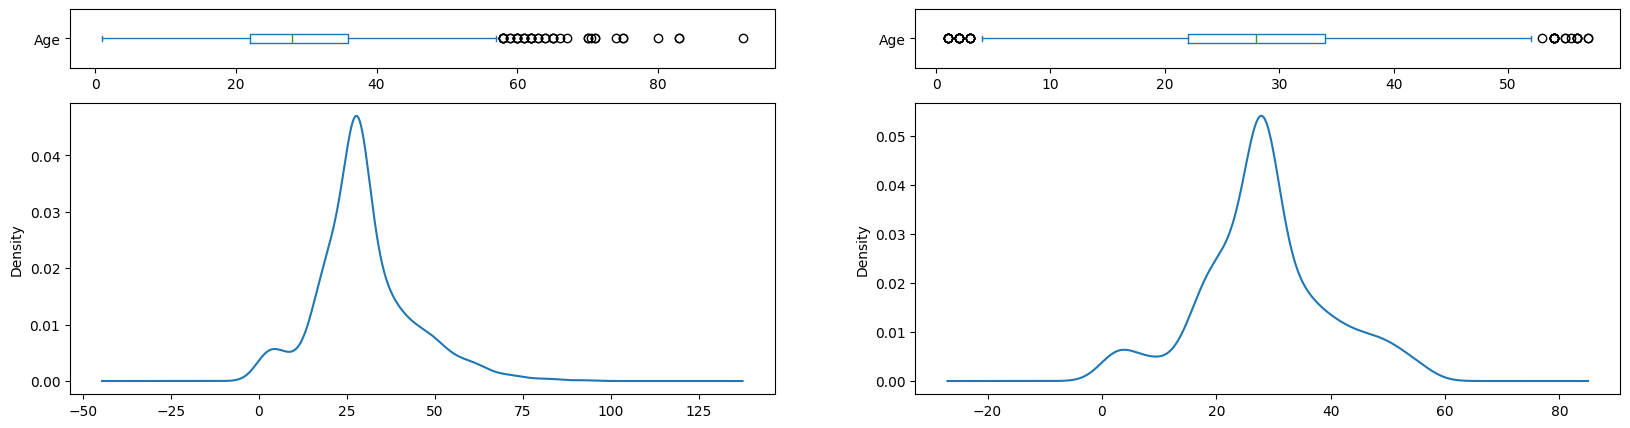

In [43]:
figure, axis = pyplot.subplots(2, 2, figsize=(20, 5), height_ratios=(1, 5))

Q1 = x1.quantile(0.25)
Q2 = x1.quantile(0.50)
Q3 = x1.quantile(0.75)
IQR = Q3 - Q1

x1.plot.box(vert=False, ax=axis[0, 0])
x1.plot.density(ax=axis[1, 0])

x1p = x1[
    (x1 >= (Q1 - 1.5 * IQR)) &
    (x1 <= (Q3 + 1.5 * IQR))
]

x1p.plot.box(vert=False, ax=axis[0, 1])
x1p.plot.density(ax=axis[1, 1])

pandas.DataFrame({
    "Min": [x1.min()],
    "Min*": [(Q1 - 1.5 * IQR)],
    "Q1": [Q1],
    "Q2": [Q2],
    "Q3": [Q3],
    "Max*": [(Q3 + 1.5 * IQR)],
    "Max": [x1.max()],
}, index=[x1.name]).T

,Fare
Min,0.0000
Min*,-26.7240
Q1,7.9104
Q2,14.4542
Q3,31.0000
Max*,65.6344
Max,512.3292


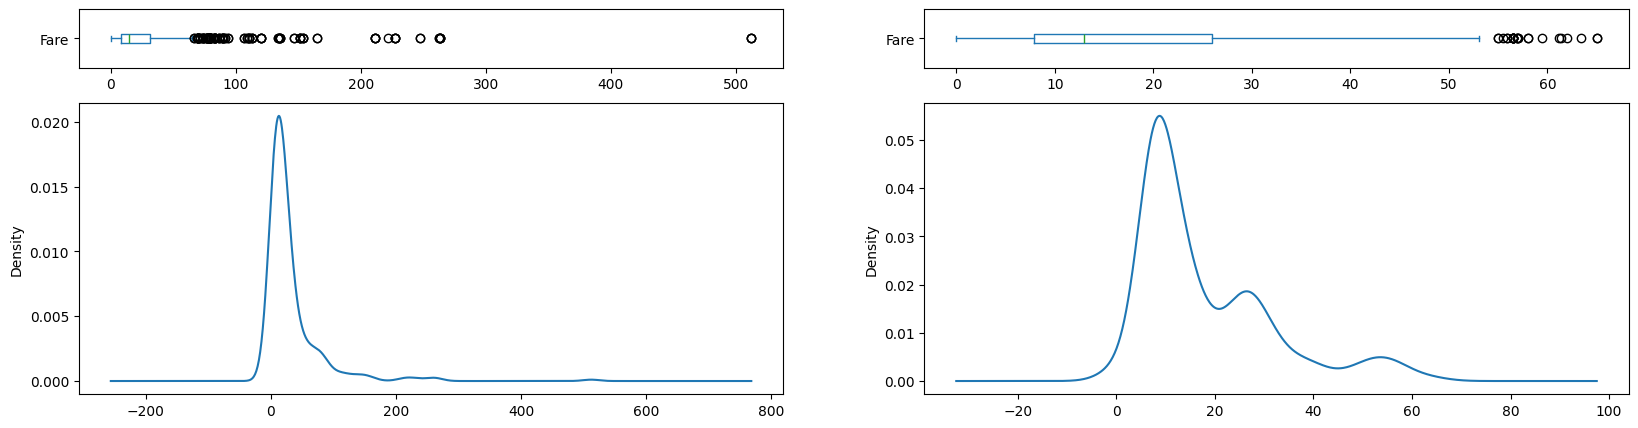

In [42]:
figure, axis = pyplot.subplots(2, 2, figsize=(20, 5), height_ratios=(1, 5))

Q1 = x2.quantile(0.25)
Q2 = x2.quantile(0.50)
Q3 = x2.quantile(0.75)
IQR = Q3 - Q1

x2.plot.box(vert=False, ax=axis[0, 0])
x2.plot.density(ax=axis[1, 0])

x2p = x2[
    (x2 >= (Q1 - 1.5 * IQR)) &
    (x2 <= (Q3 + 1.5 * IQR))
]

x2p.plot.box(vert=False, ax=axis[0, 1])
x2p.plot.density(ax=axis[1, 1])

pandas.DataFrame({
    "Min": [x2.min()],
    "Min*": [(Q1 - 1.5 * IQR)],
    "Q1": [Q1],
    "Q2": [Q2],
    "Q3": [Q3],
    "Max*": [(Q3 + 1.5 * IQR)],
    "Max": [x2.max()],
}, index=[x2.name]).T

,SibSp
Min,0.0
Min*,-1.5
Q1,0.0
Q2,0.0
Q3,1.0
Max*,2.5
Max,8.0


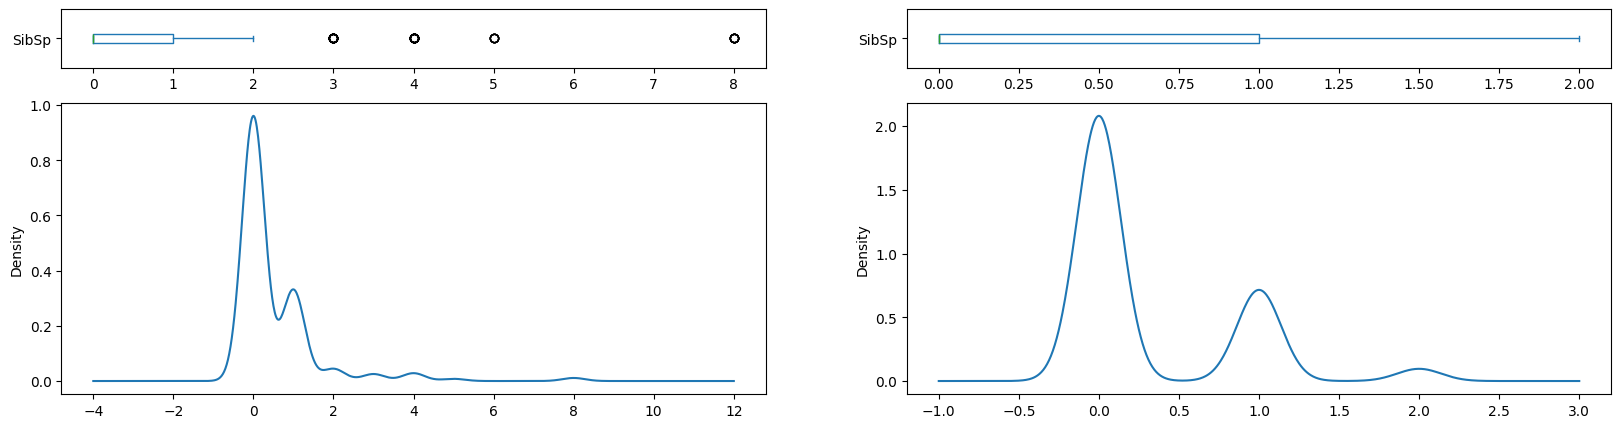

In [41]:
figure, axis = pyplot.subplots(2, 2, figsize=(20, 5), height_ratios=(1, 5))

Q1 = x3.quantile(0.25)
Q2 = x3.quantile(0.50)
Q3 = x3.quantile(0.75)
IQR = Q3 - Q1

x3.plot.box(vert=False, ax=axis[0, 0])
x3.plot.density(ax=axis[1, 0])

x3p = x3[
    (x3 >= (Q1 - 1.5 * IQR)) &
    (x3 <= (Q3 + 1.5 * IQR))
]

x3p.plot.box(vert=False, ax=axis[0, 1])
x3p.plot.density(ax=axis[1, 1])

pandas.DataFrame({
    "Min": [x3.min()],
    "Min*": [(Q1 - 1.5 * IQR)],
    "Q1": [Q1],
    "Q2": [Q2],
    "Q3": [Q3],
    "Max*": [(Q3 + 1.5 * IQR)],
    "Max": [x3.max()],
}, index=[x3.name]).T

,Parch
Min,0.0
Min*,0.0
Q1,0.0
Q2,0.0
Q3,0.0
Max*,0.0
Max,6.0


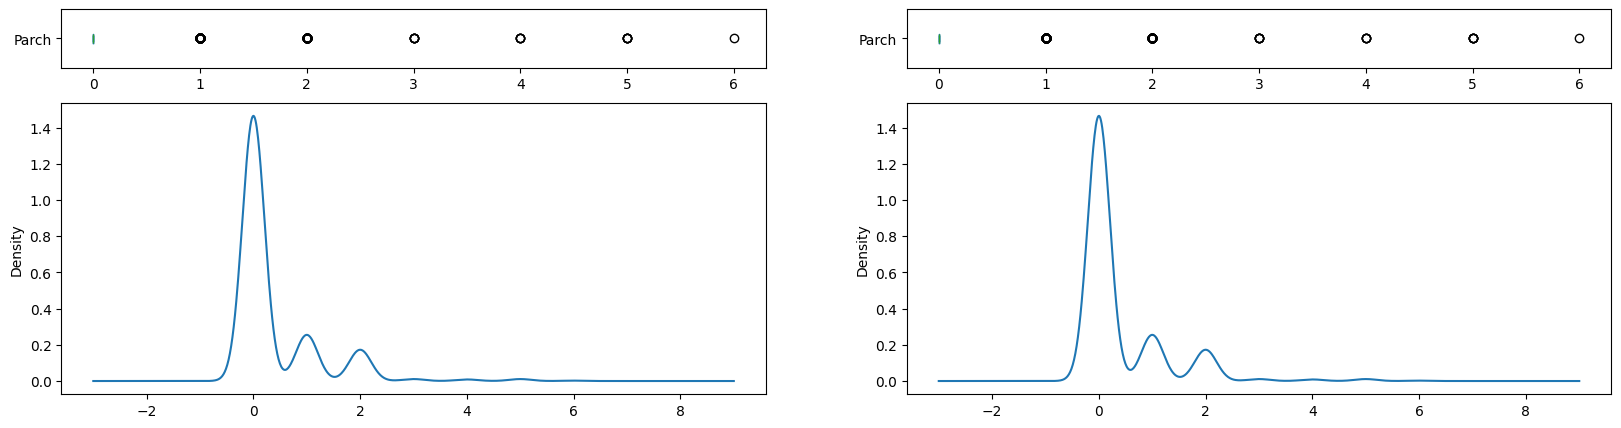

In [46]:
figure, axis = pyplot.subplots(2, 2, figsize=(20, 5), height_ratios=(1, 5))

Q1 = x4.quantile(0.25)
Q2 = x4.quantile(0.50)
Q3 = x4.quantile(0.75)
IQR = Q3 - Q1

x4.plot.box(vert=False, ax=axis[0, 0])
x4.plot.density(ax=axis[1, 0])

# x4p = x4[
#     (x4 >= (Q1 - 1.5 * IQR)) &
#     (x4 <= (Q3 + 1.5 * IQR))
# ]
x4p = x4

x4p.plot.box(vert=False, ax=axis[0, 1])
x4p.plot.density(ax=axis[1, 1])

pandas.DataFrame({
    "Min": [x4.min()],
    "Min*": [(Q1 - 1.5 * IQR)],
    "Q1": [Q1],
    "Q2": [Q2],
    "Q3": [Q3],
    "Max*": [(Q3 + 1.5 * IQR)],
    "Max": [x4.max()],
}, index=[x4.name]).T

### 3. Análisis de características discretas

In [51]:
M = pandas.concat([
    d1.value_counts(),
    d1.value_counts(normalize=True),
], axis=1)

M

,count,proportion
Survived,,
no,549,0.616162
yes,342,0.383838


<Axes: ylabel='Survived'>

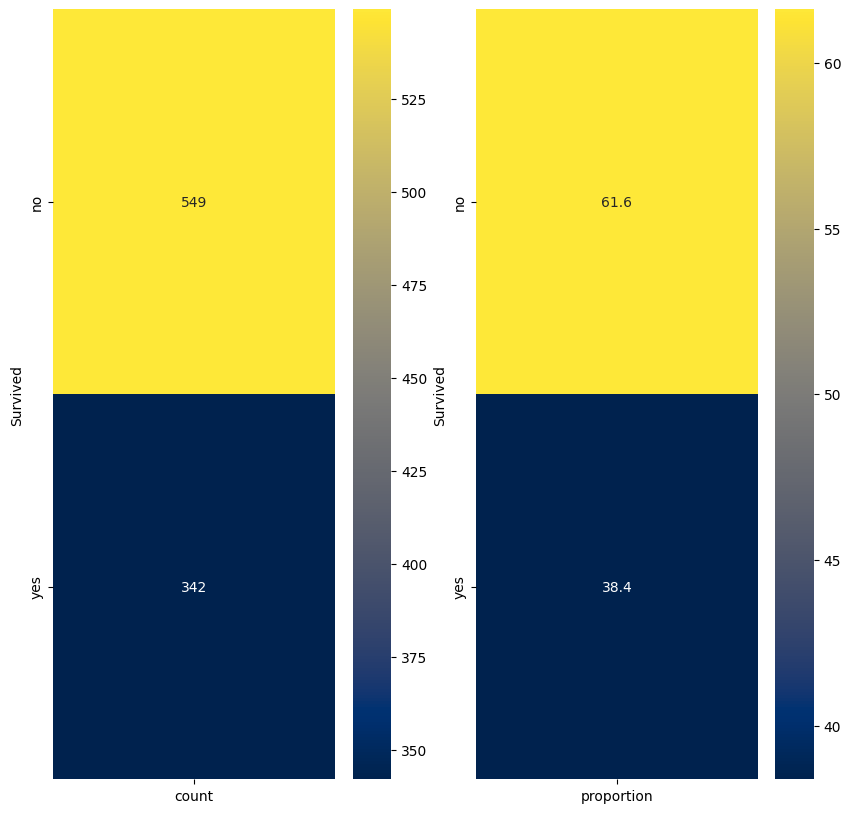

In [61]:
figure, axis = pyplot.subplots(1, 2, figsize=(10, 10))

seaborn.heatmap(M[["count"]], cmap="cividis", ax=axis[0], annot=True, fmt=".0f")
seaborn.heatmap(100 * M[["proportion"]], cmap="cividis", ax=axis[1], annot=True, fmt=".1f")

<Axes: ylabel='Pclass'>

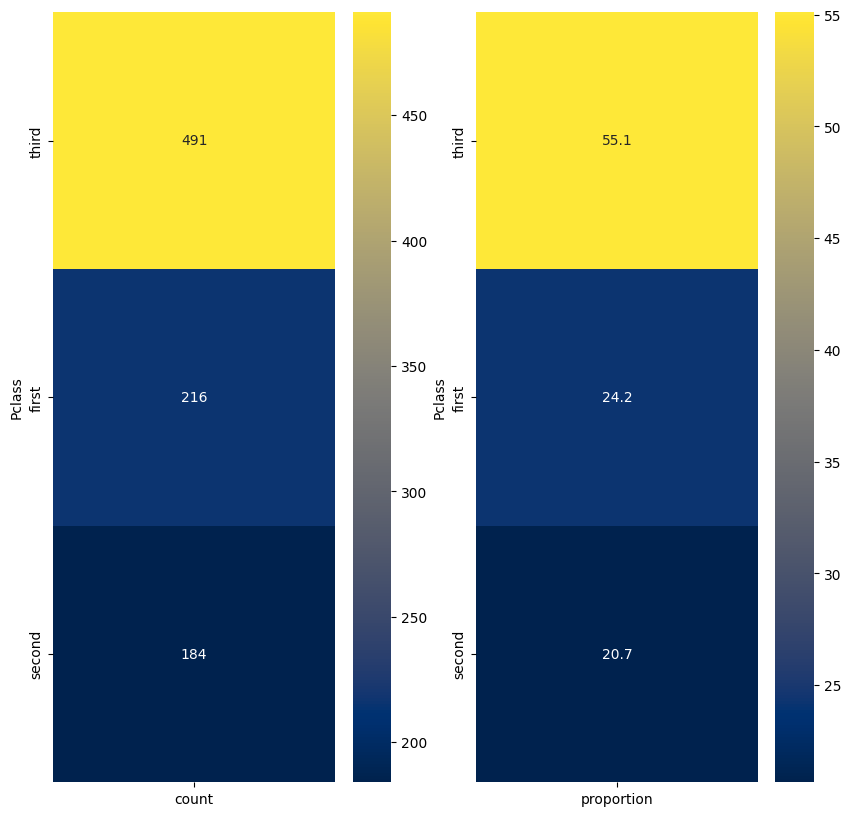

In [64]:
M = pandas.concat([
    d2.value_counts(),
    d2.value_counts(normalize=True),
], axis=1)

figure, axis = pyplot.subplots(1, 2, figsize=(10, 10))

seaborn.heatmap(M[["count"]], cmap="cividis", ax=axis[0], annot=True, fmt=".0f")
seaborn.heatmap(100 * M[["proportion"]], cmap="cividis", ax=axis[1], annot=True, fmt=".1f")

### 4. Análisis cruzado contra una respuesta continua

<Axes: xlabel='Age', ylabel='Density'>

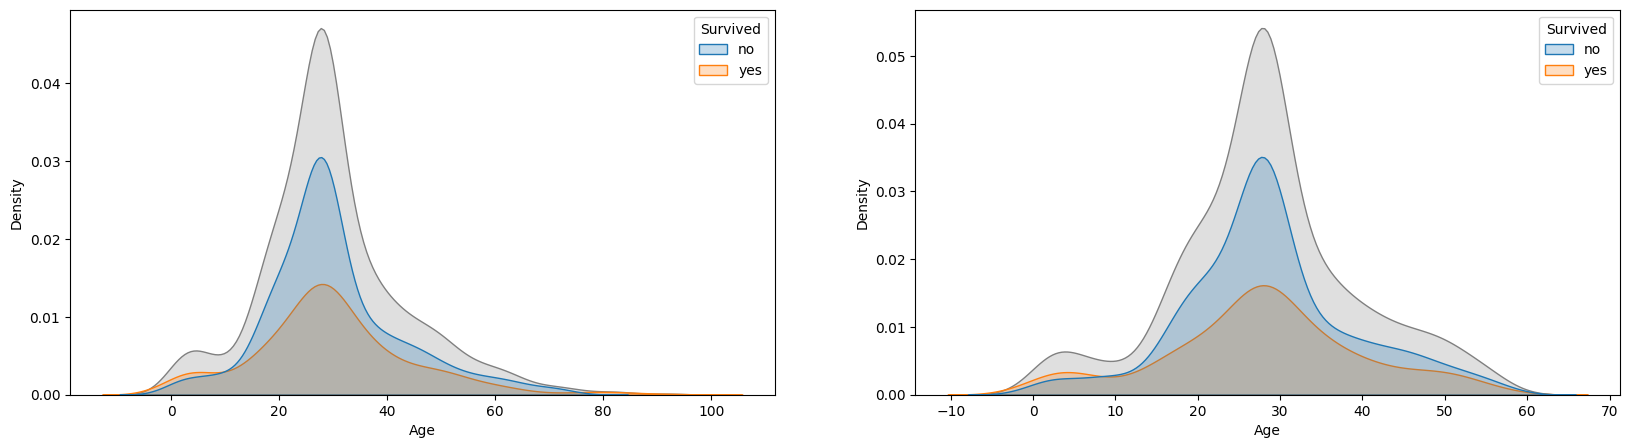

In [73]:
figure, axis = pyplot.subplots(1, 2, figsize=(20, 5))

Q1 = x1.quantile(0.25)
Q2 = x1.quantile(0.50)
Q3 = x1.quantile(0.75)
IQR = Q3 - Q1

seaborn.kdeplot(x=x1, fill=True, color="gray", ax=axis[0])
seaborn.kdeplot(x=x1, hue=d1, fill=True, color="gray", ax=axis[0])

x1p = x1[
    (x1 >= (Q1 - 1.5 * IQR)) &
    (x1 <= (Q3 + 1.5 * IQR))
]

seaborn.kdeplot(x=x1p, fill=True, color="gray", ax=axis[1])
seaborn.kdeplot(x=x1p, hue=d1, fill=True, color="gray", ax=axis[1])

<Axes: xlabel='Fare', ylabel='Density'>

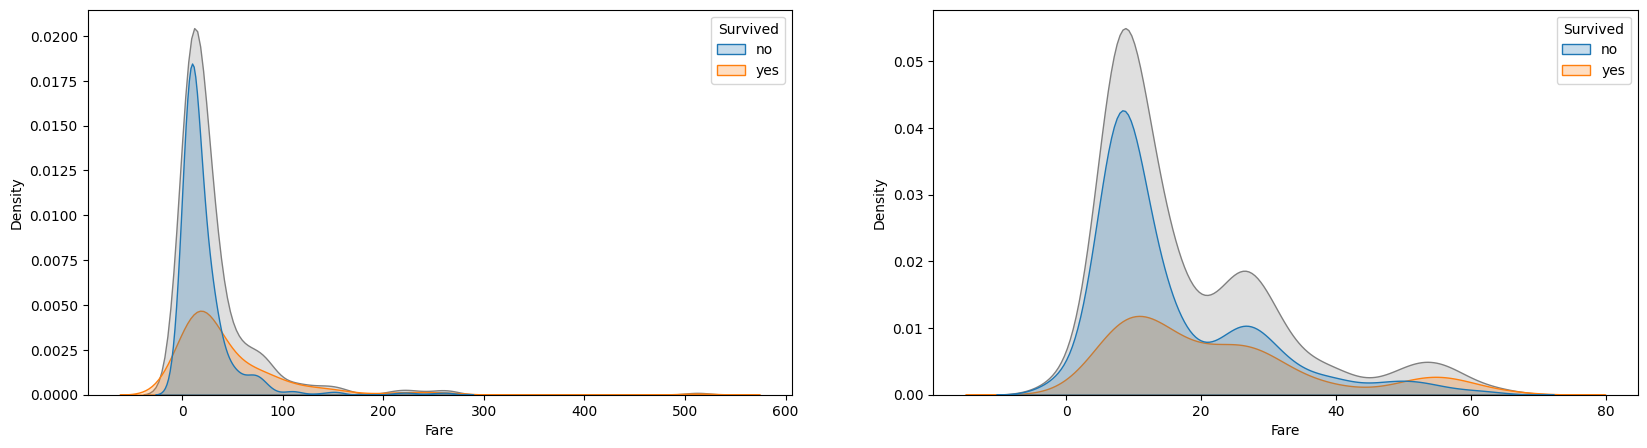

In [74]:
figure, axis = pyplot.subplots(1, 2, figsize=(20, 5))

Q1 = x2.quantile(0.25)
Q2 = x2.quantile(0.50)
Q3 = x2.quantile(0.75)
IQR = Q3 - Q1

seaborn.kdeplot(x=x2, fill=True, color="gray", ax=axis[0])
seaborn.kdeplot(x=x2, hue=d1, fill=True, color="gray", ax=axis[0])

x2p = x2[
    (x2 >= (Q1 - 1.5 * IQR)) &
    (x2 <= (Q3 + 1.5 * IQR))
]

seaborn.kdeplot(x=x2p, fill=True, color="gray", ax=axis[1])
seaborn.kdeplot(x=x2p, hue=d1, fill=True, color="gray", ax=axis[1])

### 5. Análisis cruzado contra una respuesta discreta

In [82]:
M = pandas.DataFrame([d1, d2]).T.groupby([d1.name, d2.name]).size().unstack()

M

Pclass,first,second,third
Survived,,,
no,80,97,372
yes,136,87,119


In [83]:
R1 = M.divide(M.sum(axis=1), axis=0)

R1

Pclass,first,second,third
Survived,,,
no,0.145719,0.176685,0.677596
yes,0.397661,0.254386,0.347953


In [84]:
R2 = M.divide(M.sum(axis=0), axis=1)

R2

Pclass,first,second,third
Survived,,,
no,0.37037,0.527174,0.757637
yes,0.62963,0.472826,0.242363


<Axes: xlabel='Pclass', ylabel='Survived'>

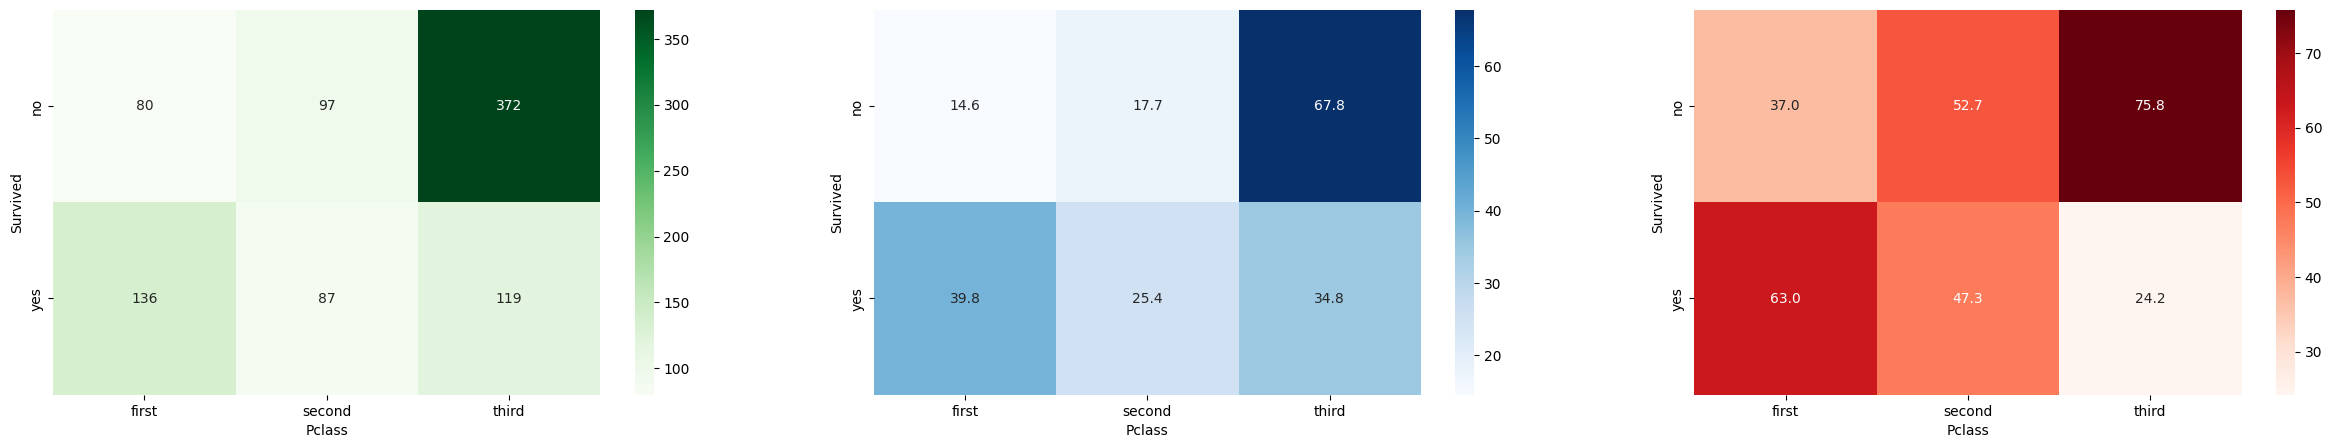

In [ ]:
figure, axis = pyplot.subplots(1, 3, figsize=(30, 5))

seaborn.heatmap(M, cmap="Greens", ax=axis[0], annot=True, fmt=".0f")
seaborn.heatmap(100 * R1, cmap="Blues", ax=axis[1], annot=True, fmt=".1f")
seaborn.heatmap(100 * R2, cmap="Reds", ax=axis[2], annot=True, fmt=".1f")

<Axes: xlabel='Sex', ylabel='Survived'>

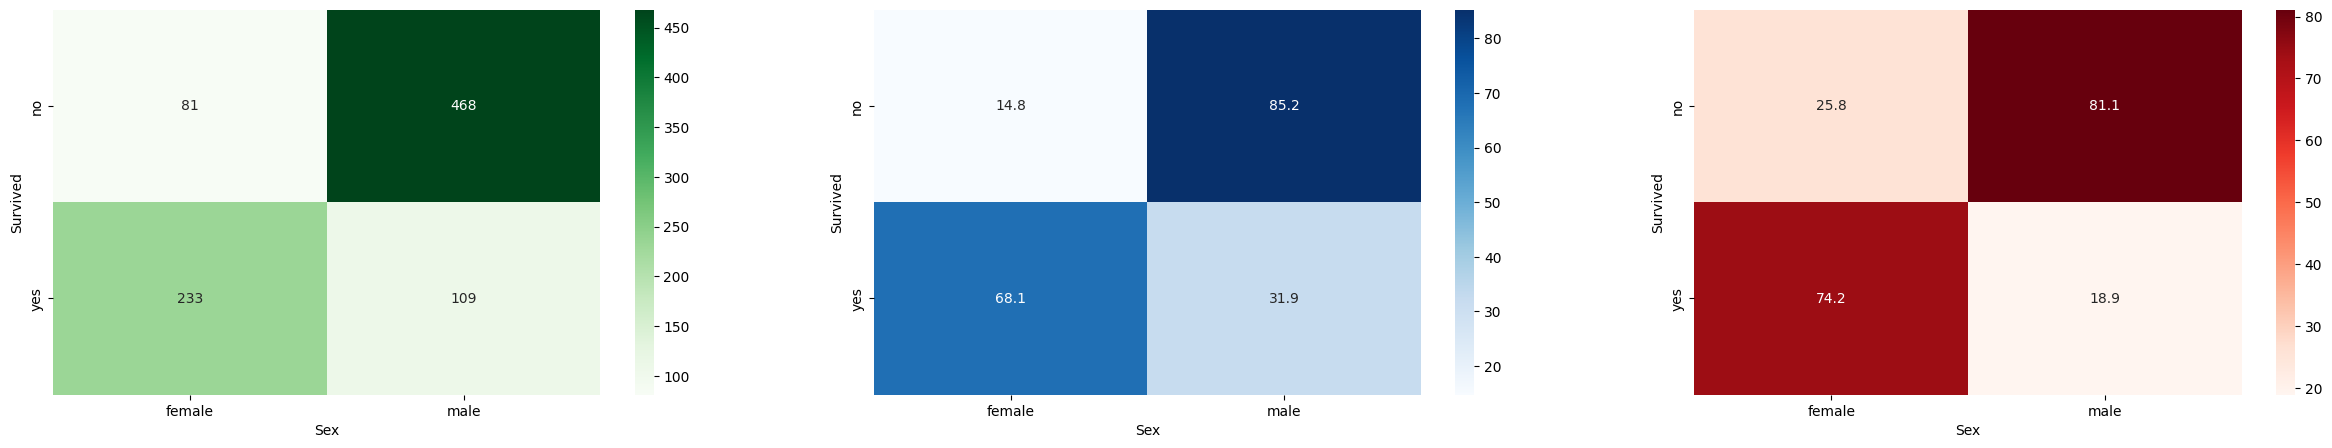

In [98]:
M = pandas.DataFrame([d1, d3]).T.groupby([d1.name, d3.name]).size().unstack()
R1 = M.divide(M.sum(axis=1), axis=0)
R2 = M.divide(M.sum(axis=0), axis=1)

figure, axis = pyplot.subplots(1, 3, figsize=(30, 5))

seaborn.heatmap(M, cmap="Greens", ax=axis[0], annot=True, fmt=".0f")
seaborn.heatmap(100 * R1, cmap="Blues", ax=axis[1], annot=True, fmt=".1f")
seaborn.heatmap(100 * R2, cmap="Reds", ax=axis[2], annot=True, fmt=".1f")